In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

In this topic we study **one variable at a time**. The aim is to summarise the
observations $x_1, x_2, \dots, x_n$ of a variable $X$ with tables, graphs and a few
numbers that describe how the data are distributed. The topic has four parts:

1. **Frequency tables and graphs** (this page).
2. [The empirical distribution, centre and position](02-centre-position.ipynb).
3. [Dispersion, shape and outliers](03-dispersion-shape.ipynb).
4. [Exercises](04-exercises.ipynb).

::: {.callout-tip}
## Learning outcomes

After this topic you should be able to:

1. Build and interpret frequency tables (absolute, relative and cumulative) for
   qualitative and quantitative variables, including data grouped into classes.
2. Choose and draw the right graph for each type of variable (bar chart, histogram,
   empirical distribution function, boxplot), and recognise graphs that distort the
   data.
3. Define and compute measures of centre, position, dispersion and shape, prove
   their main properties and know which ones are sensitive to outliers.
4. Compute quantiles and moments from grouped data, and know how linear and
   monotone transformations affect the summaries.
:::

We work with the dwellings for sale in Madrid in 2018 and the variables described
in [Topic 1](../01-introduction/02-types-of-variables.ipynb). Each row is a listing.

In [2]:
listings = pl.read_csv("data/processed/idealista/madrid_listings_2018.csv").select(
    "listing_id", "district", "zone", "condition",
    "price", "price_m2", "area_m2", "bedrooms", "bathrooms",
    "floor", "lift", "terrace", "construction_year", "dist_centre_km",
)
listings.head()

listing_id,district,zone,condition,price,price_m2,area_m2,bedrooms,bathrooms,floor,lift,terrace,construction_year,dist_centre_km
A10000037964896093228,Hortaleza,Periphery,Good,"255,000.0","2,628.9",97,3,2,4,True,False,1966,7.829
A10000072440601830803,Puente de Vallecas,Periphery,To renovate,"82,000.0","1,322.6",62,2,1,1,True,False,1965,6.435
A10000538600815177437,Puente de Vallecas,Periphery,Good,"133,000.0","1,985.1",67,3,1,3,False,True,1976,4.836
A10000654405436195291,Ciudad Lineal,Periphery,Good,"204,000.0","1,133.3",180,3,2,0,True,False,1976,4.665
A10000872160480475600,Carabanchel,Periphery,Good,"161,000.0","2,981.5",54,2,1,1,False,False,1955,4.063


::: {.callout-tip}
## Polars in one line

A Polars `DataFrame` is a table: each **column** is a variable and each **row** an
individual (here, a listing). Almost everything we do consists of selecting
columns (`pl.col(...)`) and computing something on them.
:::

## Qualitative data

### Frequency table

Let a qualitative variable $X$ with categories $c_1, \dots, c_k$ be observed on $n$
individuals.

::: {.callout-note}
## Definition

- **Absolute frequency** $n_i$: number of observations in category $c_i$. Then
  $\sum_{i=1}^k n_i = n$.
- **Relative frequency** $f_i = n_i / n$: proportion of observations in category
  $c_i$.

The set of pairs $\{(c_i, n_i)\}_{i=1}^k$, or $\{(c_i, f_i)\}_{i=1}^k$, is the
**frequency distribution** of $X$.
:::

::: {#prp-frequencies}
## Properties of frequencies
$0 \le n_i \le n$, $\ \sum_{i=1}^k n_i = n$, $\ 0 \le f_i \le 1$ and
$\sum_{i=1}^k f_i = 1$.
:::

::: {.proof}
Each of the $n$ observations belongs to exactly one category, because the categories
are mutually exclusive and exhaustive. Counting the observations category by category
therefore counts each of them once, so $\sum_i n_i = n$. Dividing by $n$ gives
$\sum_i f_i = 1$, and the bounds follow from $0 \le n_i \le n$.
:::

The two conditions on the categories, **mutually exclusive** (no observation in two
categories) and **exhaustive** (every observation in some category), are what make a
frequency table valid. A table of "features" (lift, terrace, parking…) does not
satisfy them, because a dwelling can have several features or none.

Frequency table of the district:

In [3]:
#| label: tbl-district
#| tbl-cap: "Frequency distribution of the district of the listings."
district_table = (
    listings["district"]
    .value_counts(sort=True, name="n_i")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
)
district_table

district,n_i,f_i
Centro,9233,0.122
Salamanca,6594,0.087
Carabanchel,5268,0.070
Chamberí,4986,0.066
Puente de Vallecas,4704,0.062
Tetuán,4649,0.061
Ciudad Lineal,4468,0.059
Chamartín,4031,0.053
Latina,3836,0.051
Arganzuela,3566,0.047


Centro, the historic centre, has the most listings, about one in eight. This does
not mean that it has the most dwellings: the table describes the dwellings **for
sale**, and the share of dwellings that are on the market can differ from one
district to another.

### Bar chart

A **bar chart** draws each category as a bar whose length is proportional to its
frequency. For nominal variables the bars should be **sorted by frequency**,
because the categories have no natural order.

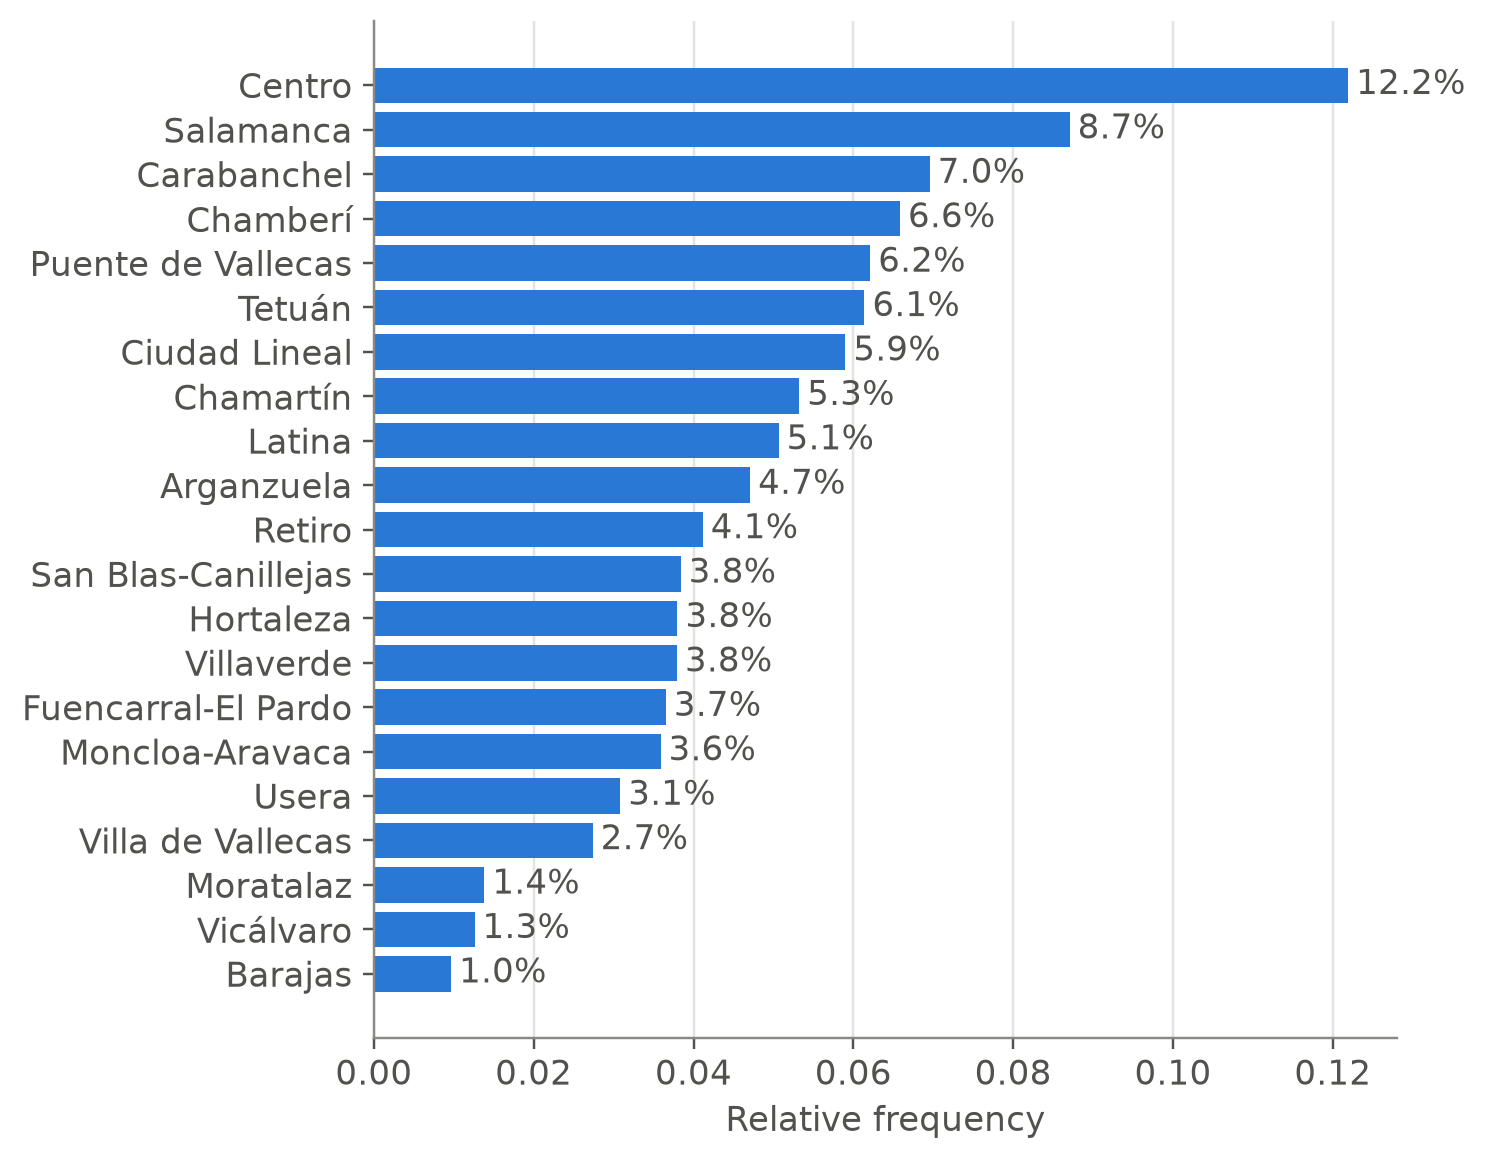

In [4]:
#| label: fig-bar-district
#| fig-cap: "Bar chart of the district of the listings (relative frequencies)."
fig, ax = plt.subplots(figsize=(6, 6))
ax.barh(district_table["district"], district_table["f_i"], color=COLORS["blue"])
ax.invert_yaxis()  # most frequent category at the top
ax.set_xlabel("Relative frequency")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for y, f in enumerate(district_table["f_i"]):
    ax.text(f + 0.001, y, f"{f:.1%}", va="center", color=COLORS["ink_soft"])
plt.show()

::: {.callout-warning}
## What about pie charts?

Pie charts are very popular, but we compare angles and areas much less accurately
than lengths on a common scale, as shown experimentally by @cleveland1984. With more
than two or three categories, a bar chart shows the same information more clearly.
:::

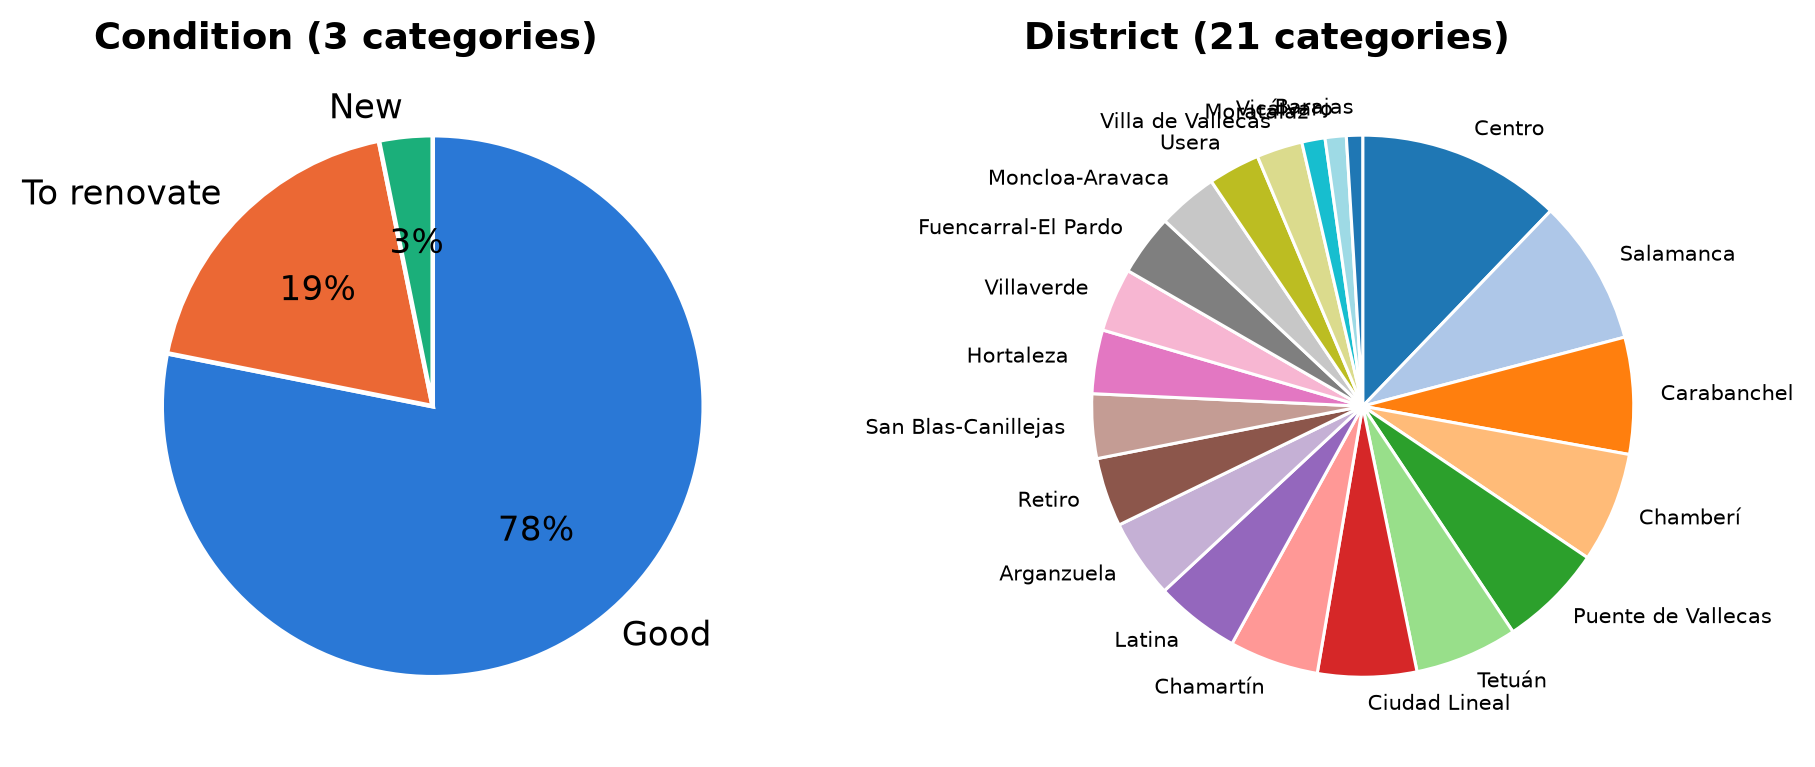

In [5]:
#| label: fig-pie-comparison
#| fig-cap: "Pie charts of the condition of the dwelling (3 categories) and of the district (21 categories)."
condition_table = (
    listings["condition"]
    .value_counts(sort=True, name="n_i")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
)

fig, (ax_cond, ax_dist) = plt.subplots(1, 2, figsize=(10, 4))

ax_cond.pie(
    condition_table["f_i"], labels=condition_table["condition"],
    autopct="%1.0f%%", startangle=90, counterclock=False,
    colors=CYCLE, wedgeprops=dict(edgecolor="white", linewidth=1.5),
)
ax_cond.set_title("Condition (3 categories)")

ax_dist.pie(
    district_table["f_i"], labels=district_table["district"],
    startangle=90, counterclock=False, textprops=dict(fontsize=7),
    colors=plt.cm.tab20.colors * 2,
    wedgeprops=dict(edgecolor="white", linewidth=1),
)
ax_dist.set_title("District (21 categories)")

for ax in (ax_cond, ax_dist):
    ax.set_aspect("equal")  # circles, not ellipses
plt.show()

With three categories, one of them clearly dominant, the pie chart works: at a
glance, about four out of five listings are second-hand dwellings in good condition.
With 21 districts it does not: many slices have similar sizes, colours repeat, and
the labels of the smallest slices are hard to read. Try to answer from the pie which
district has more listings, Latina or Arganzuela, and then check the bar chart of
@fig-bar-district.

::: {.callout-note}
## Historical note: the first bar and pie charts

Both graphs were invented by the Scottish engineer and economist William Playfair.
The bar chart appeared in his *Commercial and Political Atlas* (1786), to show
Scotland's trade with its partners, and the pie chart in his *Statistical Breviary*
(1801). Playfair also drew the first line charts of economic time series.
:::

### Graphical integrity

A graph is an argument, and it can mislead even when every number in it is correct.
@tufte1983 proposed a simple measure of distortion, the **lie factor**:
$$
\text{Lie factor} = \frac{\text{size of the effect shown in the graph}}{\text{size of the effect in the data}},
$$
where the size of an effect is the relative change between the two quantities
compared. A faithful graph has a lie factor close to 1. The most common distortion in
bar charts is a vertical axis that does not start at zero, as in the right panel of
@fig-lie-factor:

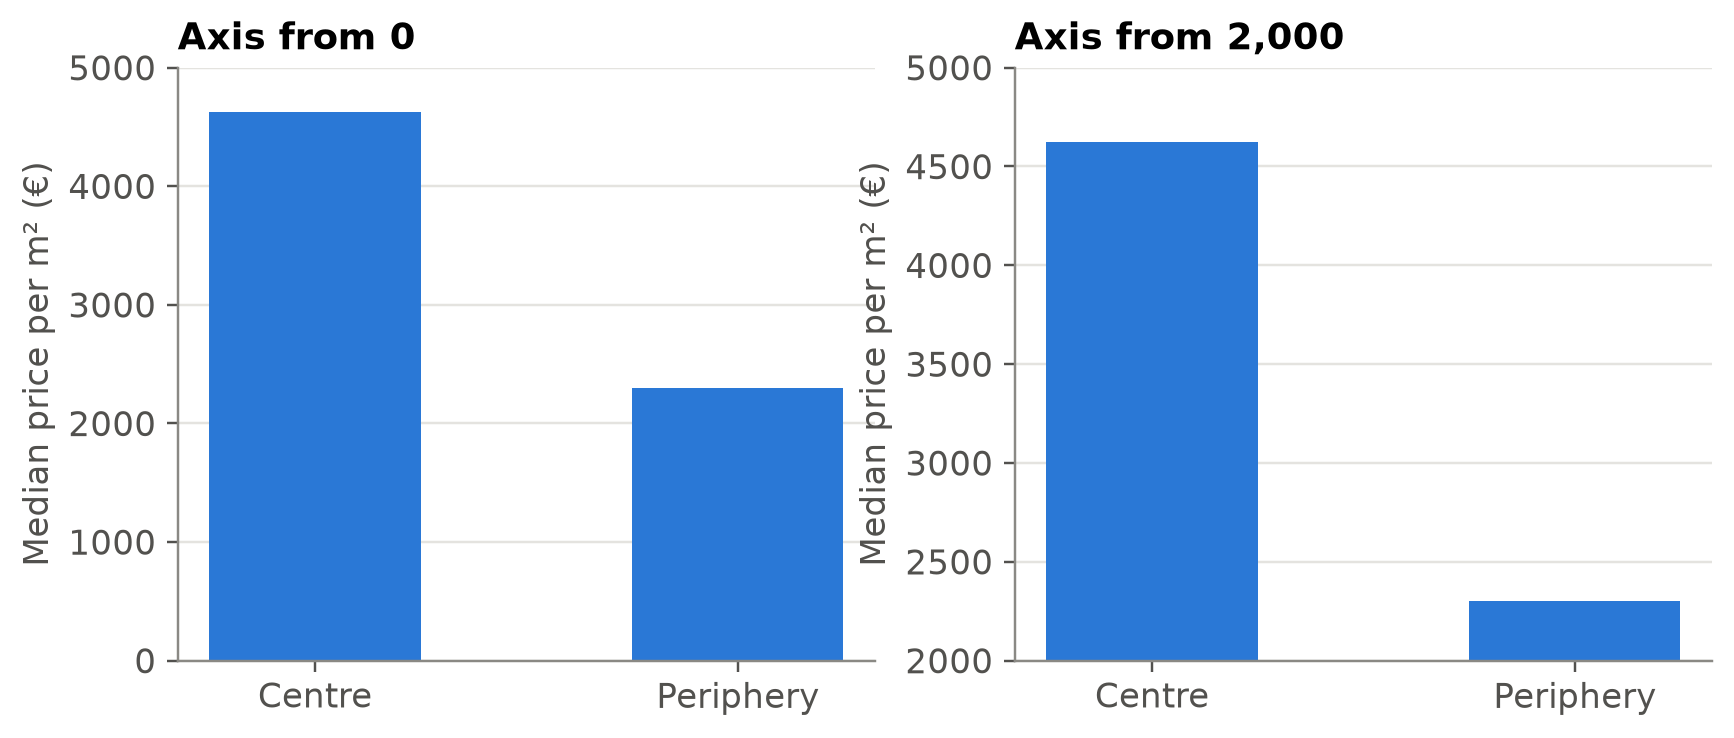

Effect in the data : the centre is 101% more expensive
Effect in the graph: the bar is 775% longer
Lie factor of the right panel: 7.7


In [6]:
#| label: fig-lie-factor
#| fig-cap: "Median asking price per m² in the centre and in the periphery. Left, axis starting at zero; right, axis starting at 2,000 €/m²."
medians = (
    listings.group_by("zone")
    .agg(median=pl.col("price_m2").median())
    .sort("zone")
)
centre, periphery = medians["median"].to_list()

fig, (ax_ok, ax_bad) = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, bottom, title in [(ax_ok, 0, "Axis from 0"), (ax_bad, 2_000, "Axis from 2,000")]:
    ax.bar(medians["zone"], medians["median"], width=0.5, color=COLORS["blue"])
    ax.set_ylim(bottom, 5_000)
    ax.set_title(title)
    ax.set_ylabel("Median price per m² (€)")
plt.show()

effect_data = (centre - periphery) / periphery
effect_graph = ((centre - 2_000) - (periphery - 2_000)) / (periphery - 2_000)
print(f"Effect in the data : the centre is {effect_data:.0%} more expensive")
print(f"Effect in the graph: the bar is {effect_graph:.0%} longer")
print(f"Lie factor of the right panel: {effect_graph / effect_data:.1f}")

In the data, the centre is about twice as expensive as the periphery; in the right
panel its bar is almost nine times as long. The rule follows from what the reader
compares: in a bar chart we compare **lengths**, so the length must be proportional to
the value, and the axis must start at zero. (Line charts, in which we compare
positions and changes, do not need a zero.) Other principles of graphical integrity:
label the axes with their units, use the same scale when panels are to be compared,
and do not encode one number with an area or a volume, whose size grows faster than
its length.

### Ordinal variables: cumulative frequencies

If the categories have a **natural order**, as the condition of the dwelling, it
makes sense to accumulate frequencies:

::: {.callout-note}
## Definition

- **Cumulative absolute frequency**: $N_i = n_1 + n_2 + \dots + n_i$.
- **Cumulative relative frequency**: $F_i = N_i / n = f_1 + \dots + f_i$.

$F_i$ is the proportion of observations whose category is $c_i$ **or lower**. It only
makes sense when the categories are ordered.
:::

By @prp-frequencies, the cumulative frequencies are non-decreasing,
$0 \le F_1 \le F_2 \le \dots \le F_k = 1$, and $f_i = F_i - F_{i-1}$ (with
$F_0 = 0$): the table of cumulative frequencies contains the same information as the
table of frequencies.

The table must follow the logical order of the categories, which we fix with
`pl.Enum`:

In [7]:
condition_order = pl.Enum(["To renovate", "Good", "New"])

condition_cum = (
    listings
    .with_columns(pl.col("condition").cast(condition_order))
    .group_by("condition")
    .agg(n_i=pl.len())
    .sort("condition")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(N_i=pl.col("n_i").cum_sum(), F_i=pl.col("f_i").cum_sum())
)
condition_cum

condition,n_i,f_i,N_i,F_i
To renovate,"14,152",0.187,"14,152",0.187
Good,"59,172",0.781,"73,324",0.968
New,2411,0.032,"75,735",1.000


For example, $F_2 \approx 0.97$ (second row): 97 % of the listings are in good
condition or need renovation, that is, are not new. New-build dwellings are only
about 3 % of the market.

## Quantitative data

### Discrete variables

A **discrete** variable with few distinct values, such as the number of bedrooms,
has a table built as for an ordinal variable, sorted by value:

In [8]:
bedrooms_table = (
    listings["bedrooms"]
    .value_counts(name="n_i")
    .sort("bedrooms")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(N_i=pl.col("n_i").cum_sum(), F_i=pl.col("f_i").cum_sum())
)
bedrooms_table

bedrooms,n_i,f_i,N_i,F_i
0,2144,0.028,2144,0.028
1,"10,688",0.141,"12,832",0.169
2,"23,057",0.304,"35,889",0.474
3,"27,210",0.359,"63,099",0.833
4,9042,0.119,"72,141",0.953
5,2564,0.034,"74,705",0.986
6,606,0.008,"75,311",0.994
7,212,0.003,"75,523",0.997
8,116,0.002,"75,639",0.999
9,30,0.000,"75,669",0.999


The table is long because of a few dwellings with many bedrooms, and its last rows
show values such as 33 or 93 bedrooms, almost certainly **errors** in the listing.
Real data contain errors; finding them is one of the first uses of a frequency
table. To summarise the distribution it is clearer to **group the tail** into a last
class "6 or more":

In [9]:
bedrooms_grouped = (
    listings
    .with_columns(
        bedrooms=pl.when(pl.col("bedrooms") >= 6).then(pl.lit("6+"))
        .otherwise(pl.col("bedrooms").cast(pl.String))
    )
    .group_by("bedrooms")
    .agg(n_i=pl.len())
    .sort("bedrooms")  # as text: "0" < "1" < … < "5" < "6+"
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
bedrooms_grouped

bedrooms,n_i,f_i,F_i
0,2144,0.028,0.028
1,"10,688",0.141,0.169
2,"23,057",0.304,0.474
3,"27,210",0.359,0.833
4,9042,0.119,0.953
5,2564,0.034,0.986
6+,1030,0.014,1.000


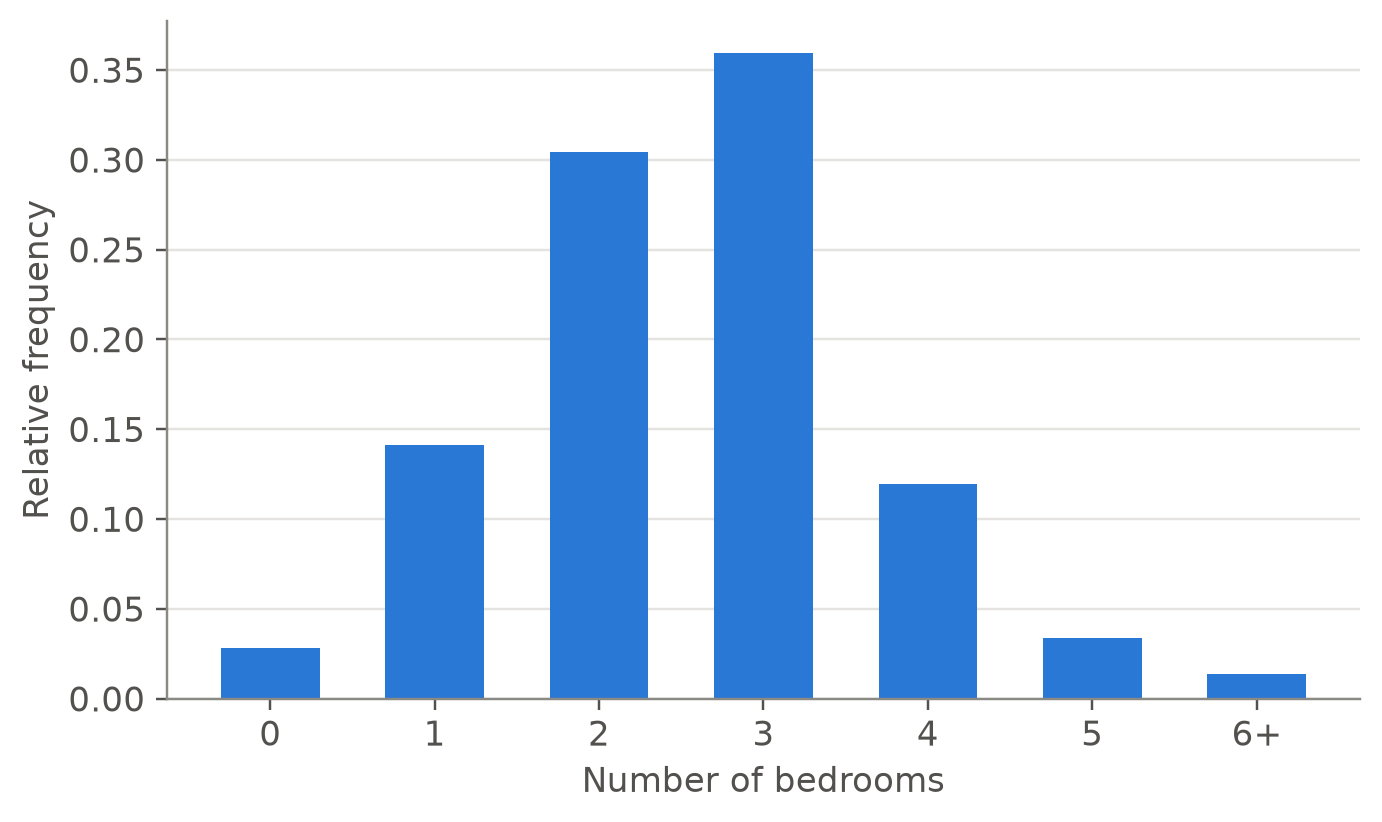

In [10]:
#| label: fig-bar-bedrooms
#| fig-cap: "Bar chart of the number of bedrooms."
fig, ax = plt.subplots()
ax.bar(bedrooms_grouped["bedrooms"], bedrooms_grouped["f_i"], width=0.6,
       color=COLORS["blue"])
ax.set_xlabel("Number of bedrooms")
ax.set_ylabel("Relative frequency")
plt.show()

Most listings have two or three bedrooms, and about 83 % have three or fewer
($F_i$ in the row of 3).

### Continuous variables: grouping into classes

A **continuous** variable such as the price takes almost as many different values as
there are observations, so a table of single values summarises nothing. The data are
grouped into **classes** (intervals) $[L_{i-1}, L_i)$, each with its **class mark**
$x_i = (L_{i-1} + L_i)/2$, the centre of the interval, and its **width**
$a_i = L_i - L_{i-1}$.

In [11]:
#| label: tbl-price-classes
#| tbl-cap: "Asking price grouped into classes of 100,000 €."
breaks = list(range(100_000, 1_000_001, 100_000))

price_table = (
    listings
    .with_columns(interval=pl.col("price").cut(breaks, left_closed=True))
    .group_by("interval")
    .agg(n_i=pl.len())
    .sort("interval")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
price_table

interval,n_i,f_i,F_i
"[-inf, 100000)",4565,0.060,0.060
"[100000, 200000)","24,398",0.322,0.382
"[200000, 300000)","14,226",0.188,0.570
"[300000, 400000)",9791,0.129,0.700
"[400000, 500000)",6197,0.082,0.781
"[500000, 600000)",4036,0.053,0.835
"[600000, 700000)",2964,0.039,0.874
"[700000, 800000)",2300,0.030,0.904
"[800000, 900000)",1686,0.022,0.926
"[900000, 1000000)",1115,0.015,0.941


::: {.callout-tip}
## Polars detail

`cut()` creates intervals closed on the right, $(a, b]$, unless `left_closed=True`
is given, as here. The first and last intervals are open ($-\infty$ and $\infty$), so
that every observation falls into one class.
:::

Reading the column $F_i$: about 38 % of the listings ask for less than 200,000 €, and
about 90 % ask for less than 800,000 €.

### Histogram

The **histogram** is the graph of a grouped variable: each class is drawn as a
rectangle over its interval. When all the classes have the **same width**, the height
of each rectangle can be its absolute frequency $n_i$ or its relative frequency
$f_i$. Both versions have the same shape; only the scale of the vertical axis
changes.

With Seaborn, the function `sns.histplot` draws both: the argument `stat` chooses
what goes on the vertical axis (`"count"` for $n_i$, `"probability"` for $f_i$).

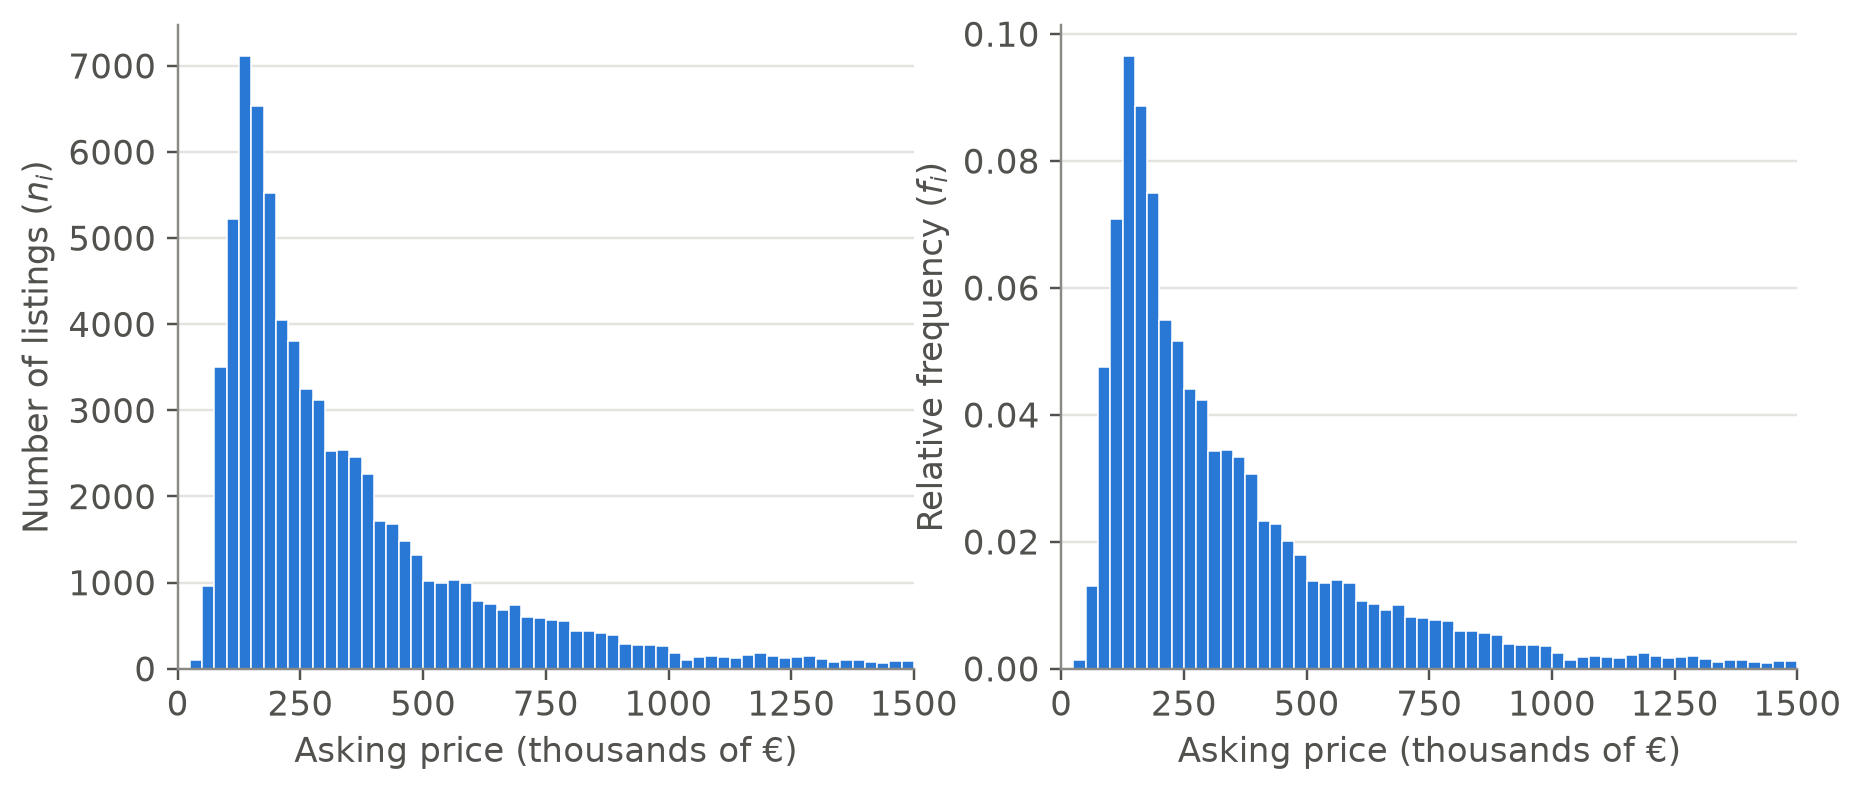

In [12]:
#| label: fig-hist-price
#| fig-cap: "Histogram of the asking price in classes of 25,000 €, with absolute frequencies (left) and relative frequencies (right). The horizontal axis stops at 1.5 million €: a few listings lie further to the right."
price = listings["price"].to_numpy() / 1000  # thousands of €
bins = np.arange(0, 1_525, 25)

fig, (ax_abs, ax_rel) = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, stat, label in [(ax_abs, "count", "Number of listings ($n_i$)"),
                        (ax_rel, "probability", "Relative frequency ($f_i$)")]:
    sns.histplot(x=price, bins=bins, stat=stat, ax=ax,
                 color=COLORS["blue"], edgecolor="white", linewidth=0.5, alpha=1)
    ax.set_xlim(0, 1_500)
    ax.set_xlabel("Asking price (thousands of €)")
    ax.set_ylabel(label)
plt.show()

@fig-hist-price shows a **right-skewed** distribution: about two thirds of the dwellings ask between
100,000 and 400,000 €, and a long tail of dwellings asks for much more (the most
expensive, more than 8 million €). This is the typical shape of prices, incomes and
wealth.

#### Classes of different widths

Sometimes it is convenient to use classes of **different widths**, for example a
wide class in the tail, where there are few observations. Then the height of a
rectangle cannot be its frequency: a wide class collects many observations simply
because it is wide. The rectangles must be drawn so that their **area** is
proportional to the frequency, so the height of rectangle $i$ is the **density**
$$
h_i = \frac{f_i}{a_i},
$$ {#eq-histogram-density}
where $a_i$ is the width of the class. In `sns.histplot` this is `stat="density"`.

::: {#prp-histogram-area}
## Areas of a density histogram
In a histogram with heights $h_i = f_i / a_i$, the area of each rectangle is the
relative frequency of its class, and the total area is 1. More generally, the area
over any union of classes is the proportion of observations in those classes.
:::

::: {.proof}
The area of rectangle $i$ is $a_i h_i = a_i \cdot f_i / a_i = f_i$. Adding over the
classes, the total area is $\sum_i f_i = 1$ by @prp-frequencies, and the area over a
union of classes is the sum of their $f_i$.
:::

The density $h_i$ has units: proportion of observations **per unit of the variable**
(here, per thousand euros). This is what makes histograms with different classes
comparable, and what will connect them with the density functions of probability.

@fig-hist-unequal uses classes of 100,000 € up to 600,000 € and a single class from
600,000 € to 1.5 million €.

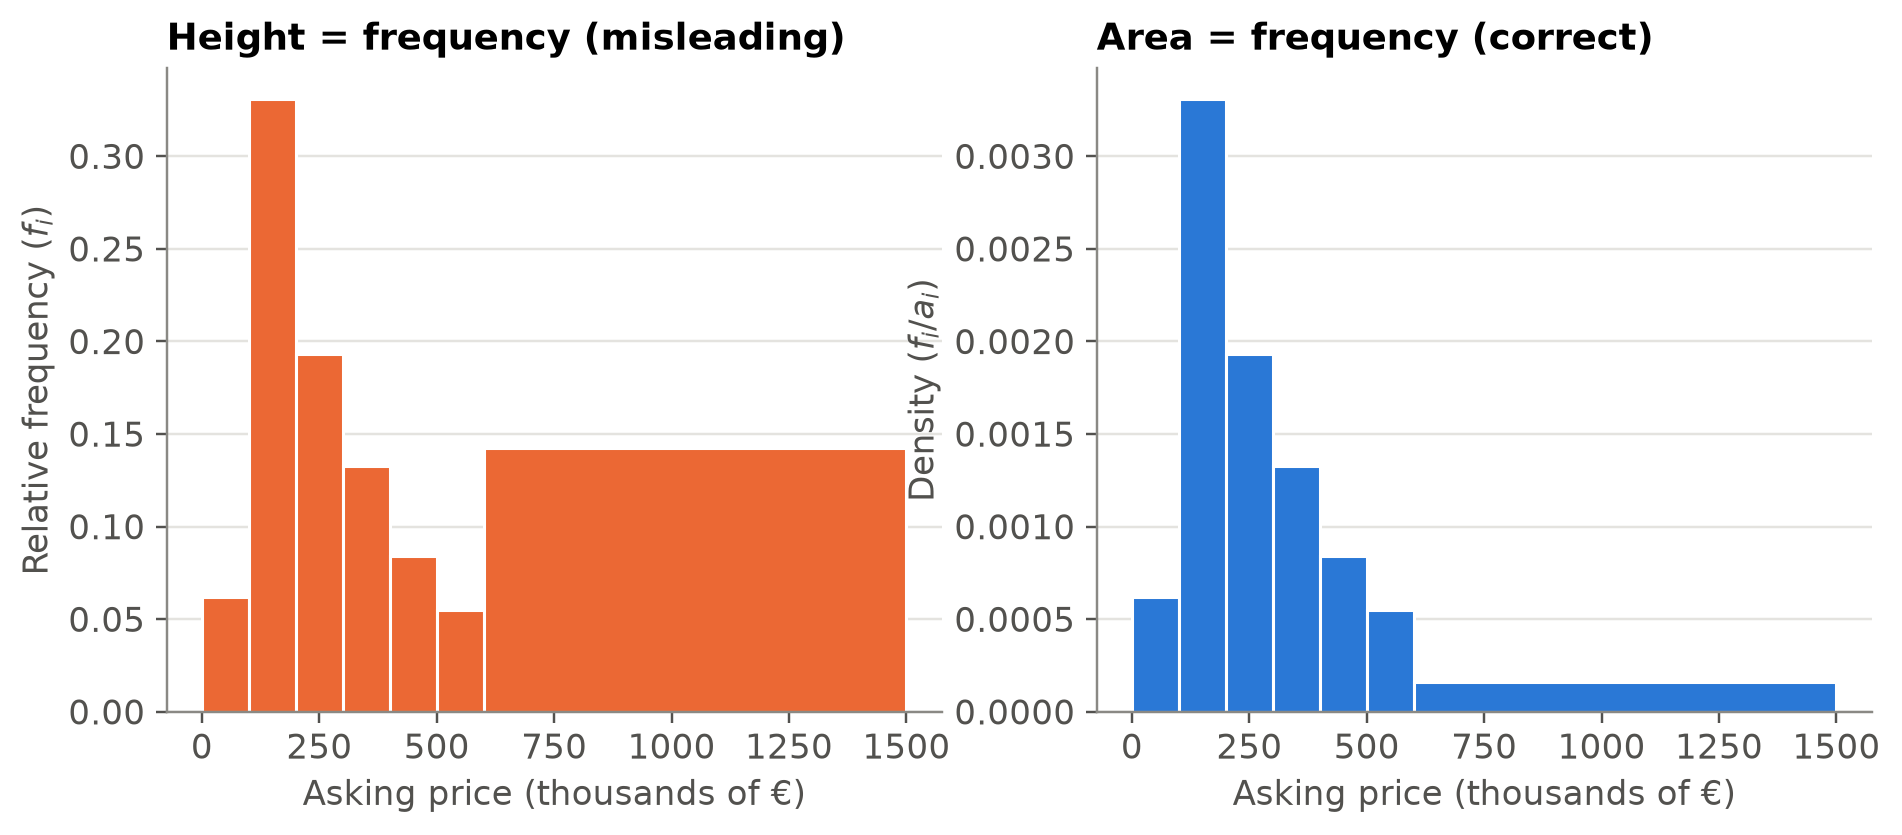

In [13]:
#| label: fig-hist-unequal
#| fig-cap: "The same classes of different widths drawn with relative frequencies (left) and with densities (right). Only the density histogram represents the data correctly."
bins_unequal = [0, 100, 200, 300, 400, 500, 600, 1_500]

fig, (ax_f, ax_d) = plt.subplots(1, 2, figsize=(10, 3.8))
sns.histplot(x=price, bins=bins_unequal, stat="probability", ax=ax_f,
             color=COLORS["orange"], edgecolor="white", linewidth=1, alpha=1)
ax_f.set_ylabel("Relative frequency ($f_i$)")
ax_f.set_title("Height = frequency (misleading)")

sns.histplot(x=price, bins=bins_unequal, stat="density", ax=ax_d,
             color=COLORS["blue"], edgecolor="white", linewidth=1, alpha=1)
ax_d.set_ylabel("Density ($f_i / a_i$)")
ax_d.set_title("Area = frequency (correct)")

for ax in (ax_f, ax_d):
    ax.set_xlabel("Asking price (thousands of €)")
plt.show()

Drawn with its frequency (left), the last class suggests that many dwellings cost
more than 600,000 €, only because that class is nine times wider than the others: its
rectangle is nine times too tall.
Drawn with its density (right), each 100,000 € of that class holds few listings, and
the tail decreases as it should.

::: {.callout-warning}
## Data outside the classes

`sns.histplot` (like `plt.hist`) leaves out the observations outside all the
classes, here the listings above 1.5 million €, and computes the relative
frequencies with the remaining ones.
:::

::: {.callout-important}
## The number of classes matters

Too few classes hide the shape of the distribution; too many make it noisy. A
classical guide is **Sturges' rule**, $k \approx 1 + \log_2 n$ [@sturges1926],
although with large data sets it gives too few classes (about 17 for our 75,735
listings). Sturges derived it for data with a symmetric, bell-shaped distribution, which
our prices do not have. In practice it is worth trying several widths and choosing the one
that shows the shape best.
:::

::: {.callout-note}
## Historical note: the word "histogram"

The term *histogram* was coined by Karl Pearson, who used it in his lectures in the
early 1890s and in print in 1895, in his work on skewed distributions
[@pearson1895]. Pearson was trying to describe biological and economic data whose
distributions, like the prices of @fig-hist-price, were far from the symmetric
normal curve.
:::

## References {.unnumbered}

::: {#refs}
:::